# Portfolio optimisation of 20 US stocks: Markowitz model, QUBO, simulated annealing, MIQP and the Ising spin-glass model

**What this notebook does (in order)**

1. **Data** - downloads the daily *adjusted closing prices* from Yahoo Finance **once** (cell 1); every later cell uses that table.
2. **Markowitz model** - expected returns μ, covariance Σ, Sharpe-ratio charts, efficient frontier, minimum-variance and maximum-Sharpe portfolios.
3. **QUBO formulation** - choose exactly *k* of the 20 stocks (equal weights 1/k): the Markowitz objective plus a penalty for the constraint Σx = k.
4. **Classical solvers** - simulated annealing on the QUBO, and exact MIQP (Gurobi, SCIP as fallback).
5. **Ising spin-glass model** - the same QUBO rewritten with spins s ∈ {−1,+1} (couplings J, fields h) and solved by simulated annealing on the Ising energy.
6. **Comparison** - table, charts and a statement comparing simulated annealing (QUBO), the Ising spin-glass model and MIQP.

**Mathematics used throughout**

* μ = 252 · mean(daily simple returns), Σ = 252 · cov(daily simple returns), full period (no train/test split).
* Mean-variance objective: f(w) = (λ/2) wᵀΣw − μᵀw, with λ = (R_t − RF)/σ_t² (the value for which the max-Sharpe portfolio is the continuous optimum).
* QUBO: H(x) = (λ/2)(xᵀΣx)/k² − μᵀx/k + P (Σxᵢ − k)², xᵢ ∈ {0,1}, weight of a chosen stock = 1/k.
* Ising: xᵢ = (1+sᵢ)/2 gives E(s) = Σ_{i<j} Jᵢⱼ sᵢ sⱼ + Σᵢ hᵢ sᵢ + offset.

## 1. Settings and data download (the only cell that calls Yahoo Finance)

* All adjustable numbers are at the top of the cell (dates, risk-free rates, annealing size, number of repeated runs, MIQP limits).
* `download_adj_close` requests the **Adj Close** column (split- *and* dividend-adjusted, `auto_adjust=False`), retries tickers that fail, and returns a *Date × Ticker* table `adj_close`.
* `RF = 0` is used in the optimisation and `RF_CHART = 0.02` only for the Sharpe-ratio charts - the same two values as in your original cells.

In [1]:
import os, sys, time, itertools, warnings, io
from math import comb
from itertools import combinations, islice

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy import stats
from IPython.display import display

warnings.filterwarnings("ignore")
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

# ------------------------------------------------------------------ settings (everything adjustable is here)
START_DATE  = "2000-01-01"      # first day requested from Yahoo Finance
END_DATE    = "2026-01-01"      # Yahoo 'end' is exclusive -> last day = 2025-12-31
MAX_RETRIES = 3                 # download retries
TD          = 252               # trading days per year
RF          = 0.0               # risk-free rate used in the optimisation (max-Sharpe, lambda), as in your Markowitz cell
RF_CHART    = 0.02              # risk-free rate used only for the Sharpe-ratio charts, as in your Sharpe-chart cell
MAX_W       = 0.30              # cap per stock for the continuous Markowitz portfolios (as in your files)
SEED        = 42
OUT_DIR     = "outputs_20stocks"     # figures / tables are saved here

N_RANDOM    = 10000          # random long-only portfolios drawn behind the efficient frontier
FRONT_PTS   = 60         # points on the efficient frontier
LABEL_N     = 20           # how many stocks get a text label in the charts
K_GRID      = list(range(1, 21))            # candidate numbers of stocks k scanned by the QUBO
MC_N, MC_RUNS = 5000, 200           # Monte Carlo penalty estimate: random binary vectors per run, number of runs
SA_CHAINS   = 128         # parallel annealing chains per run
SA_SWEEPS   = 150         # sweeps per chain
N_SEEDS     = 30           # independent repeated runs of every annealer (different random seeds)
EXACT_LIMIT = 300000                # exhaustive search over all C(N,k) subsets only if C(N,k) <= this
ENUM_LIMIT  = 40000                 # exhaustive convex-QP check of the MIQP only if C(N,k) <= this
MIQP_TIME_LIMIT = None   # seconds (None = no limit)
MIQP_GAP    = 1e-9             # relative MIP gap tolerance

os.makedirs(OUT_DIR, exist_ok=True)
def savefig(name):
    plt.savefig(f"{OUT_DIR}/{name}.png", dpi=200, bbox_inches="tight")

import yfinance as yf

def download_adj_close(tickers, start, end, chunk=50, retries=MAX_RETRIES):
    """Daily ADJUSTED CLOSE (split + dividend adjusted, auto_adjust=False -> 'Adj Close') for every ticker.
    Tickers are requested in chunks; tickers that fail are requested again (Yahoo sometimes fails transiently)."""
    got = {}
    def fetch(batch):
        df = yf.download(list(batch), start=start, end=end, interval="1d", auto_adjust=False,
                         progress=False, threads=True)
        if df is None or df.empty:
            return
        if isinstance(df.columns, pd.MultiIndex):
            adj = df["Adj Close"]
        else:
            adj = df[["Adj Close"]]; adj.columns = list(batch)[:1]
        for t in adj.columns:
            s = adj[t].dropna()
            if len(s):
                got[t] = s
    for attempt in range(1, retries + 1):
        todo = [t for t in tickers if t not in got]
        if not todo:
            break
        print(f"download attempt {attempt}/{retries}: {len(todo)} ticker(s) to fetch")
        for i in range(0, len(todo), chunk):
            try:
                fetch(todo[i:i + chunk])
            except Exception as e:
                print("  error:", e)
        time.sleep(2 * attempt)
    failed = [t for t in tickers if t not in got]
    out = pd.DataFrame({t: got[t] for t in tickers if t in got}).sort_index()
    out.index = pd.to_datetime(out.index); out.index.name = "Date"
    if failed:
        print(f"WARNING - no data for {len(failed)} ticker(s): {failed}")
    return out

# ---------------------------------------------------------------- the 20 stocks

STOCKS = {                       # Yahoo Finance uses a hyphen for share classes: BRK.B -> BRK-B
    "MSFT": "Microsoft Corporation", "AAPL": "Apple Inc.", "NVDA": "NVIDIA Corporation", "AMZN": "Amazon.com Inc.",
    "INTC": "Intel Corporation", "WMT": "Walmart Inc.", "KO": "The Coca-Cola Company", "DIS": "The Walt Disney Company",
    "PG": "The Procter & Gamble Company", "IBM": "International Business Machines", "MCD": "McDonald's Corporation",
    "JPM": "JPMorgan Chase & Co.", "GS": "The Goldman Sachs Group, Inc.", "MS": "Morgan Stanley",
    "AXP": "American Express Company", "BAC": "Bank of America Corporation", "JNJ": "Johnson & Johnson",
    "XOM": "ExxonMobil Corporation", "UNH": "UnitedHealth Group Incorporated", "BRK-B": "Berkshire Hathaway Inc. (Class B)",
}
TICKERS = list(STOCKS)

# ---------------------------------------------------------------- download ONCE (nothing else in this notebook calls Yahoo)
adj_close = download_adj_close(TICKERS, START_DATE, END_DATE)      # DOWNLOAD-LINE
adj_close.to_csv("adj_close_wide.csv")

summary = pd.DataFrame({"Name": pd.Series(STOCKS), "Rows": adj_close.count(),
                        "First date": adj_close.apply(lambda s: s.first_valid_index().date()),
                        "Last date": adj_close.apply(lambda s: s.last_valid_index().date()),
                        "Missing": adj_close.isna().sum()})
print(f"\nSuccessful: {adj_close.shape[1]}/{len(TICKERS)} stocks | {len(adj_close)} trading days "
      f"({adj_close.index[0].date()} to {adj_close.index[-1].date()})")
display(summary)

download attempt 1/3: 20 ticker(s) to fetch

Successful: 20/20 stocks | 6539 trading days (2000-01-03 to 2025-12-31)


,Name,Rows,First date,Last date,Missing
MSFT,Microsoft Corporation,6539,2000-01-03,2025-12-31,0
AAPL,Apple Inc.,6539,2000-01-03,2025-12-31,0
NVDA,NVIDIA Corporation,6539,2000-01-03,2025-12-31,0
AMZN,Amazon.com Inc.,6539,2000-01-03,2025-12-31,0
INTC,Intel Corporation,6539,2000-01-03,2025-12-31,0
WMT,Walmart Inc.,6539,2000-01-03,2025-12-31,0
KO,The Coca-Cola Company,6539,2000-01-03,2025-12-31,0
DIS,The Walt Disney Company,6539,2000-01-03,2025-12-31,0
PG,The Procter & Gamble Company,6539,2000-01-03,2025-12-31,0
IBM,International Business Machines,6539,2000-01-03,2025-12-31,0


## 2. Returns, expected returns μ and covariance matrix Σ

* Daily simple returns rₜ = Pₜ/Pₜ₋₁ − 1 from the adjusted closes; only days on which every stock has a return are kept.
* **μ** (annualised mean) and **Σ** (annualised covariance) are computed **once** here and are the inputs of *every* optimiser below.
* The check that Σ is positive definite (smallest eigenvalue > 0) guarantees that the objective is convex.

In [2]:
# daily simple returns, computed ONCE from the adjusted closes downloaded in cell 1
returns = adj_close.pct_change().iloc[1:]
n_rows  = len(returns)
returns = returns.dropna()                       # keep only days on which every stock has a return
tickers = list(returns.columns)
N       = len(tickers)

mu    = returns.mean().to_numpy() * TD           # annualised mean return (arithmetic)   mu_i
Sigma = returns.cov().to_numpy() * TD            # annualised covariance matrix           Sigma_ij
ev_min = np.linalg.eigvalsh(Sigma).min()
assert ev_min > 0, "covariance matrix is not positive definite"

print(f"{N} stocks | {returns.index[0].date()} to {returns.index[-1].date()} | {len(returns)} daily returns "
      f"({n_rows - len(returns)} rows dropped for missing values)")
print(f"smallest eigenvalue of Sigma = {ev_min:.3e} (> 0: positive definite)")

20 stocks | 2000-01-04 to 2025-12-31 | 6538 daily returns (0 rows dropped for missing values)
smallest eigenvalue of Sigma = 1.989e-02 (> 0: positive definite)


## 3. Sharpe-ratio charts

Sharpe ratio of a single stock: SR = (μᵢ − RF)/σᵢ with RF = `RF_CHART`.

* **Figure 1** - annualised return vs volatility, colour = Sharpe ratio, dashed lines = constant Sharpe ratio.
* **Figure 2** - ranking of return, volatility and Sharpe ratio.
* **Figure 3** - correlation matrix of daily returns (the off-diagonal structure of Σ).

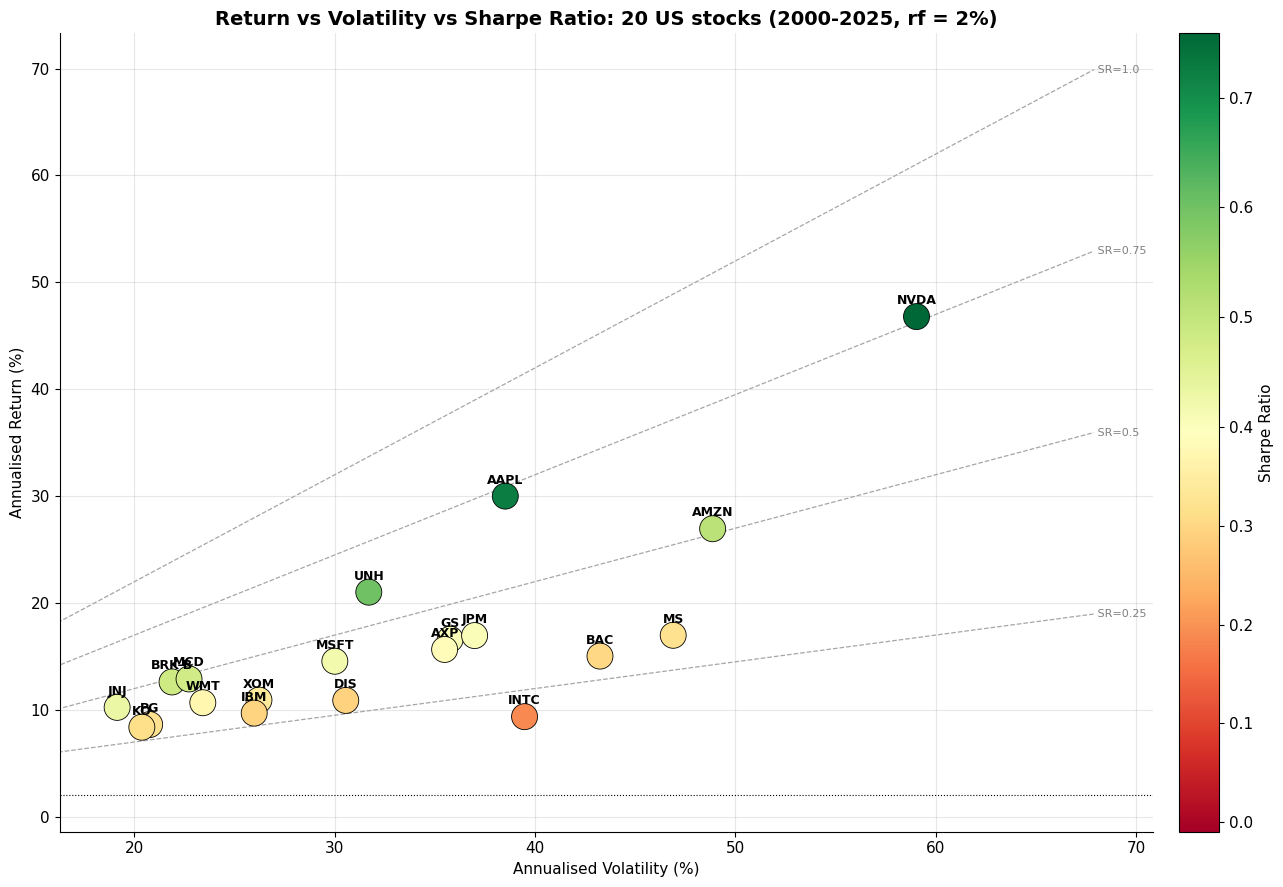

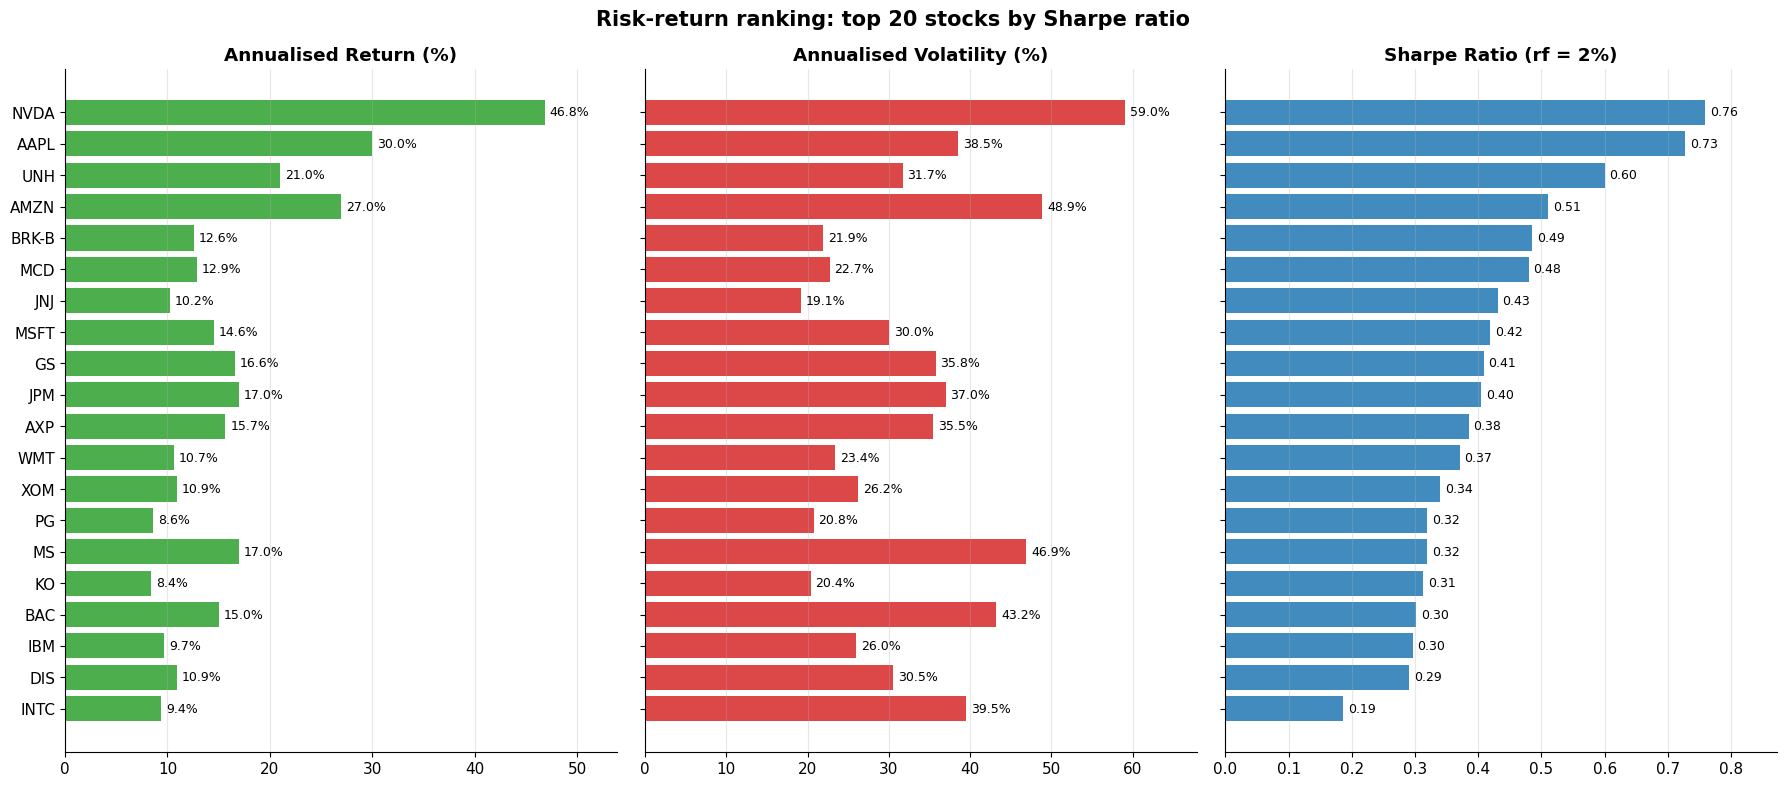

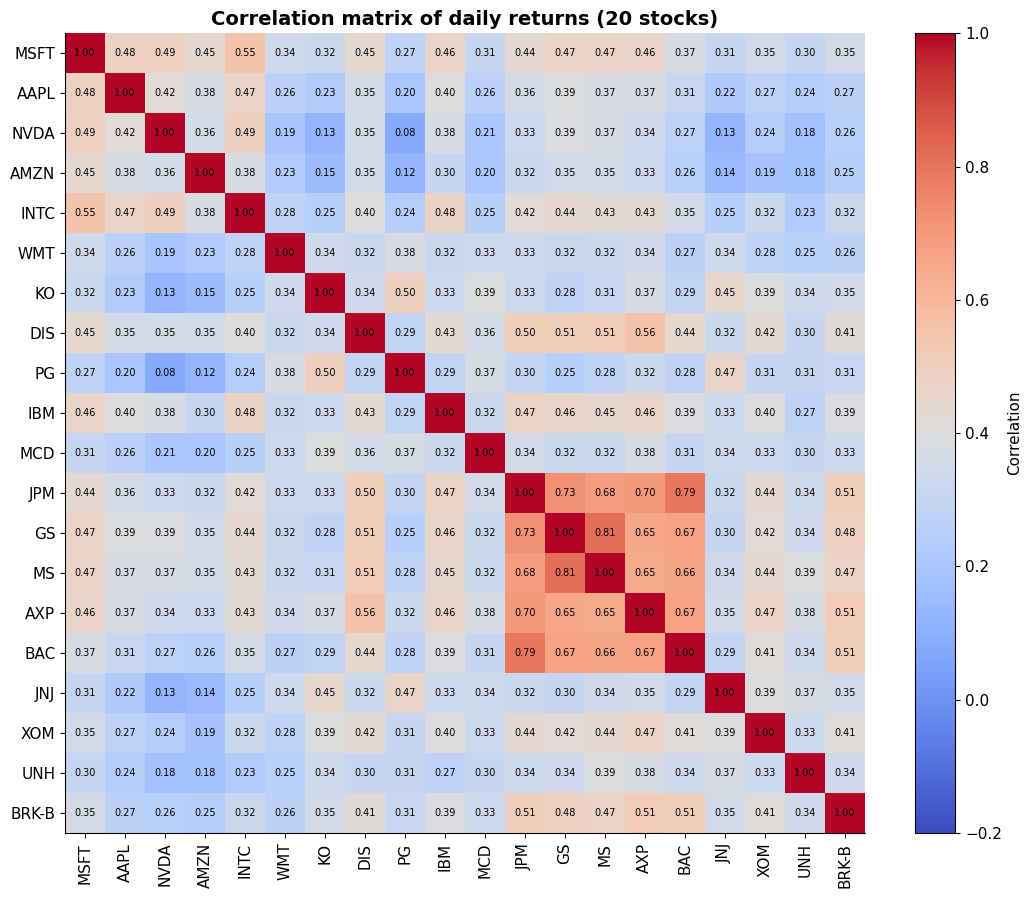

Top 20 stocks by Sharpe ratio (rf = 2%):


,Ann. Return (%),Ann. Volatility (%),Sharpe Ratio
NVDA,46.80,59.05,0.76
AAPL,30.00,38.52,0.73
UNH,21.02,31.70,0.60
AMZN,26.95,48.87,0.51
BRK-B,12.62,21.88,0.49
MCD,12.90,22.73,0.48
JNJ,10.24,19.14,0.43
MSFT,14.55,30.00,0.42
GS,16.61,35.76,0.41
JPM,16.96,36.98,0.40


In [3]:
from matplotlib.colors import TwoSlopeNorm
vol_i   = np.sqrt(np.diag(Sigma))
sharpe_i = (mu - RF_CHART) / vol_i
metrics = pd.DataFrame({"Ann. Return (%)": mu * 100, "Ann. Volatility (%)": vol_i * 100,
                        "Sharpe Ratio": sharpe_i}, index=tickers).sort_values("Sharpe Ratio", ascending=False)

# FIGURE 1: return vs volatility, coloured by Sharpe ratio, with iso-Sharpe lines
fig, ax = plt.subplots(figsize=(14, 9))
x, y, s = metrics["Ann. Volatility (%)"], metrics["Ann. Return (%)"], metrics["Sharpe Ratio"]
norm = TwoSlopeNorm(vmin=min(s.min(), -0.01), vcenter=s.median(), vmax=s.max())
sc = ax.scatter(x, y, c=s, cmap="RdYlGn", norm=norm, s=350, edgecolor="black", linewidth=0.6, zorder=3)
for t in metrics.index[:LABEL_N]:
    ax.annotate(t, (x[t], y[t]), xytext=(0, 9), textcoords="offset points", ha="center", fontsize=9, fontweight="bold")
xs_ = np.linspace(0, x.max() * 1.15, 100)
for sh in [0.25, 0.5, 0.75, 1.0]:
    ax.plot(xs_, (RF_CHART + sh * xs_ / 100) * 100, ls="--", lw=0.9, color="grey", alpha=0.7, zorder=1)
    ax.text(xs_[-1], (RF_CHART + sh * xs_[-1] / 100) * 100, f" SR={sh}", fontsize=8, color="grey", va="center")
ax.axhline(RF_CHART * 100, color="black", lw=0.8, ls=":")
plt.colorbar(sc, ax=ax, pad=0.02).set_label("Sharpe Ratio")
ax.set_xlim(x.min() * 0.85, x.max() * 1.2)
ax.set_xlabel("Annualised Volatility (%)"); ax.set_ylabel("Annualised Return (%)"); ax.grid(True, alpha=0.3)
ax.set_title(f"Return vs Volatility vs Sharpe Ratio: {N} US stocks ({returns.index[0].year}-{returns.index[-1].year}, rf = {RF_CHART:.0%})"
             + (f"  [labels: top {LABEL_N} by Sharpe]" if N > LABEL_N else ""), fontsize=14, fontweight="bold")
plt.tight_layout(); savefig("sharpe_return_vs_volatility"); plt.show()

# FIGURE 2: ranking of return, volatility and Sharpe ratio (top stocks by Sharpe)
top = metrics.head(LABEL_N).iloc[::-1]
fig, axes = plt.subplots(1, 3, figsize=(18, 8), sharey=True)
for a, (col_, ttl, c) in zip(axes, [("Ann. Return (%)", "Annualised Return (%)", "#2ca02c"),
                                    ("Ann. Volatility (%)", "Annualised Volatility (%)", "#d62728"),
                                    ("Sharpe Ratio", f"Sharpe Ratio (rf = {RF_CHART:.0%})", "#1f77b4")]):
    v = top[col_]
    a.barh(top.index, v, color=c, alpha=0.85)
    for i, val in enumerate(v):
        a.text(val + v.max() * 0.01, i, f"{val:.2f}" if col_ == "Sharpe Ratio" else f"{val:.1f}%", va="center", fontsize=9)
    a.set_title(ttl, fontweight="bold"); a.grid(True, axis="x", alpha=0.3); a.set_xlim(right=v.max() * 1.15)
plt.suptitle(f"Risk-return ranking: top {len(top)} stocks by Sharpe ratio", fontsize=15, fontweight="bold")
plt.tight_layout(); savefig("sharpe_ranking"); plt.show()

# FIGURE 3: correlation matrix of daily returns
corr = returns.corr().to_numpy()
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr, cmap="coolwarm", vmin=-0.2, vmax=1)
if N <= 25:
    ax.set_xticks(range(N)); ax.set_xticklabels(tickers, rotation=90); ax.set_yticks(range(N)); ax.set_yticklabels(tickers)
    for i in range(N):
        for j in range(N):
            ax.text(j, i, f"{corr[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(im, ax=ax, label="Correlation")
ax.set_title(f"Correlation matrix of daily returns ({N} stocks)", fontsize=14, fontweight="bold")
plt.tight_layout(); savefig("correlation_matrix"); plt.show()

print(f"Top {min(LABEL_N, N)} stocks by Sharpe ratio (rf = {RF_CHART:.0%}):")
display(metrics.head(LABEL_N).round(2))

## 4. Markowitz portfolio model (long-only, fully invested, weight cap 30 %)

* **Minimum variance:** min wᵀΣw  s.t. Σw = 1, 0 ≤ wᵢ ≤ 0.30.
* **Maximum Sharpe (tangency):** max (μᵀw − RF)/√(wᵀΣw)  s.t. the same constraints. It is solved as an equivalent convex QP (substitute y = w/((μ−RF)ᵀw): minimise yᵀΣy s.t. (μ−RF)ᵀy = 1, y ≥ 0, then w = y/Σy; the cap becomes yᵢ ≤ 0.30·Σy and is only added if it is binding). This gives the same optimum as the direct Sharpe maximisation but converges reliably for 500 stocks.
* **Efficient frontier:** for a grid of target returns, minimise the variance (SLSQP).
* The cloud of random long-only portfolios (Dirichlet weights) shows the feasible set; the frontier is its upper-left boundary.
* The tables list individual statistics, the two optimised portfolios and their weights. The max-Sharpe portfolio gives the risk-aversion λ of the QUBO in the next section.

Markowitz (min-variance, max-Sharpe, 60-point frontier) solved in 0.3 s


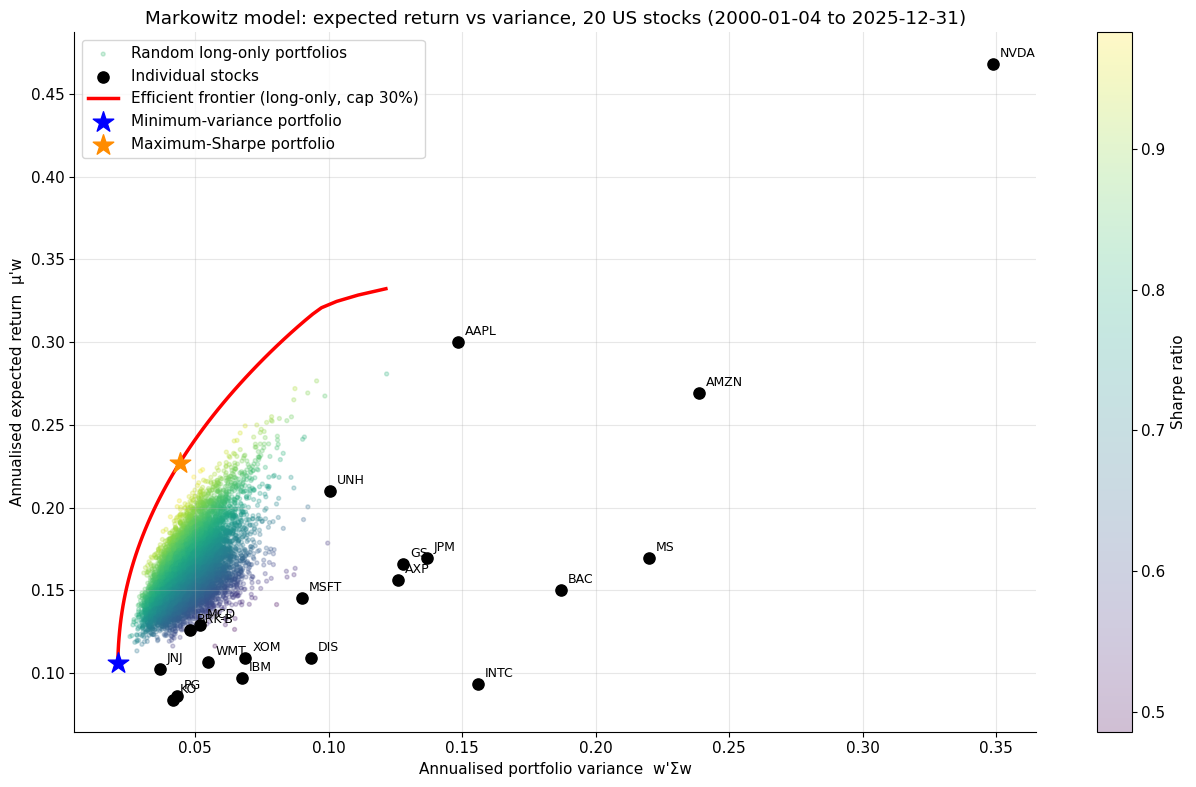

Individual stock statistics (top 20 by expected return):


,Expected Return (%),Variance,Volatility (%)
NVDA,46.7991,0.3486,59.0466
AAPL,30.0030,0.1483,38.5158
AMZN,26.9526,0.2388,48.8677
UNH,21.0171,0.1005,31.7003
MS,16.9816,0.2199,46.8986
JPM,16.9557,0.1368,36.9836
GS,16.6119,0.1279,35.7646
AXP,15.6572,0.1259,35.4864
BAC,15.0344,0.1870,43.2430
MSFT,14.5550,0.0900,30.0046


Optimised portfolios:


,Portfolio,Expected Return (%),Variance,Volatility (%),Sharpe Ratio,No. of stocks (w > 0.01%)
0,Equal weight (1/N),16.2444,0.0441,21.0050,0.7734,20
1,Minimum variance,10.6308,0.0210,14.4868,0.7338,10
2,Maximum Sharpe,22.7163,0.0442,21.0181,1.0808,9


Weights (only stocks with weight > 0.01% in either portfolio):


,Min-variance weight (%),Max-Sharpe weight (%)
UNH,0.00,19.79
AAPL,0.07,17.79
JNJ,23.93,15.72
NVDA,0.00,15.20
MCD,12.18,13.47
BRK-B,16.98,9.70
AMZN,0.51,4.19
WMT,12.50,2.36
PG,13.05,1.78
IBM,5.03,0.00


In [4]:
# ---- portfolio functions (long-only, fully invested, capped at MAX_W) --------------------------------
def equal_weight(n):
    return np.full(n, 1.0 / n)

def _slsqp(fun, jac, n, cap, starts):
    cons = [{"type": "eq", "fun": lambda w: np.sum(w) - 1.0, "jac": lambda w: np.ones(n)}]
    best = None
    for w0 in starts:
        res = minimize(fun, w0, jac=jac, method="SLSQP", bounds=[(0.0, cap)] * n,
                       constraints=cons, options={"maxiter": 1000, "ftol": 1e-12})
        if res.success and (best is None or res.fun < best.fun):
            best = res
    if best is None:
        raise RuntimeError("SLSQP did not converge")
    w = np.clip(best.x, 0.0, cap)
    return w / w.sum()

def min_variance(Sigma, cap):
    n = len(Sigma)
    return _slsqp(lambda w: w @ Sigma @ w, lambda w: 2 * Sigma @ w, n, cap, [equal_weight(n)])

def mean_variance(mu, Sigma, lam, cap):
    """minimise lam/2 w'Sigma w - mu'w  (the objective that the QUBO encodes)"""
    n = len(mu)
    return _slsqp(lambda w: 0.5 * lam * w @ Sigma @ w - mu @ w, lambda w: lam * Sigma @ w - mu,
                  n, cap, [equal_weight(n), min_variance(Sigma, cap)])

def max_sharpe(mu, Sigma, cap, rf=RF):
    """Maximum-Sharpe (tangency) portfolio, solved as a convex quadratic program.
    With y = w / ((mu - rf)'w) the problem  max (mu-rf)'w / sqrt(w'Sigma w)  becomes
        minimise y'Sigma y   s.t.  (mu - rf)'y = 1,  y >= 0   (and  y_i <= cap * sum(y)  if the cap is binding),   w = y / sum(y)."""
    n = len(mu); ex = mu - rf
    if ex.max() <= 0:
        raise ValueError("no stock has an expected return above the risk-free rate")
    y0 = np.full(n, 1.0 / ex.sum()) if ex.sum() > 0 else np.eye(n)[int(np.argmax(ex))] / ex.max()
    def solve(with_cap):
        cons = [{"type": "eq", "fun": lambda y: ex @ y - 1.0, "jac": lambda y: ex}]
        if with_cap:
            cons.append({"type": "ineq", "fun": lambda y: cap * y.sum() - y, "jac": lambda y: cap * np.ones((n, n)) - np.eye(n)})
        res = minimize(lambda y: y @ Sigma @ y, y0, jac=lambda y: 2 * Sigma @ y, method="SLSQP",
                       bounds=[(0.0, None)] * n, constraints=cons, options={"maxiter": 1000, "ftol": 1e-14})
        if not res.success:
            raise RuntimeError(f"max-Sharpe QP did not converge: {res.message}")
        w = np.clip(res.x, 0.0, None)
        return w / w.sum()
    w = solve(False)                       # without the cap; if some weight exceeds the cap, solve again with the cap
    return solve(True) if w.max() > cap + 1e-9 else w

def mv_objective(w, mu, Sigma, lam):
    return 0.5 * lam * w @ Sigma @ w - mu @ w

def port_stats(w):
    """(expected return, variance, volatility, Sharpe with RF)"""
    ret, var = float(mu @ w), float(w @ Sigma @ w)
    return ret, var, np.sqrt(var), (ret - RF) / np.sqrt(var)

def frontier_points(mu, Sigma, cap, n_pts):
    """Long-only efficient frontier (variance ascending, return non-decreasing)."""
    n = len(mu)
    w_min = min_variance(Sigma, cap)
    order, w_hi, left = np.argsort(-mu), np.zeros(n), 1.0
    for i in order:                                       # highest return reachable under the cap
        take = min(cap, left); w_hi[i] = take; left -= take
        if left <= 1e-12:
            break
    pts, w_prev = [], w_min
    for tr in np.linspace(mu @ w_min, mu @ w_hi, n_pts)[:-1]:
        cons = [{"type": "eq", "fun": lambda w: np.sum(w) - 1.0, "jac": lambda w: np.ones(n)},
                {"type": "eq", "fun": lambda w, tr=tr: mu @ w - tr, "jac": lambda w: mu}]
        res = minimize(lambda w: w @ Sigma @ w, w_prev, jac=lambda w: 2 * Sigma @ w, method="SLSQP",
                       bounds=[(0.0, cap)] * n, constraints=cons, options={"maxiter": 1000, "ftol": 1e-12})
        if res.success:
            pts.append((res.fun, tr)); w_prev = res.x
    pts.append((w_hi @ Sigma @ w_hi, mu @ w_hi))
    pts = np.array(pts); pts = pts[np.argsort(pts[:, 0])]
    return pts[:, 0], np.maximum.accumulate(pts[:, 1])

# ---- solutions --------------------------------------------------------------------------------------
t0 = time.time()
w_ew     = equal_weight(N)
w_minvar = min_variance(Sigma, MAX_W)
w_maxsh  = max_sharpe(mu, Sigma, MAX_W)
t_markowitz = time.time() - t0
f_var, f_ret = frontier_points(mu, Sigma, MAX_W, FRONT_PTS)
print(f"Markowitz (min-variance, max-Sharpe, {FRONT_PTS}-point frontier) solved in {time.time() - t0:.1f} s")

# ---- random long-only portfolios (feasible set) -------------------------------------------------------
rng = np.random.default_rng(SEED)
rw    = rng.dirichlet(np.ones(N), size=N_RANDOM)
r_ret = rw @ mu
r_var = ((rw @ Sigma) * rw).sum(axis=1)
r_sh  = (r_ret - RF) / np.sqrt(r_var)

ret_mv, var_mv, vol_mv, sh_mv = port_stats(w_minvar)
ret_ms, var_ms, vol_ms, sh_ms = port_stats(w_maxsh)

# ---- chart: expected return vs variance ---------------------------------------------------------------
plt.figure(figsize=(13, 8))
sc = plt.scatter(r_var, r_ret, c=r_sh, cmap="viridis", s=8, alpha=0.25, label="Random long-only portfolios")
plt.scatter(np.diag(Sigma), mu, color="black", s=65, zorder=4, label="Individual stocks")
if N <= 25:
    for name, v, r in zip(tickers, np.diag(Sigma), mu):
        plt.annotate(name, (v, r), xytext=(5, 5), textcoords="offset points", fontsize=9)
plt.plot(f_var, f_ret, color="red", lw=2.5, label=f"Efficient frontier (long-only, cap {MAX_W:.0%})")
plt.scatter(var_mv, ret_mv, color="blue", marker="*", s=240, zorder=5, label="Minimum-variance portfolio")
plt.scatter(var_ms, ret_ms, color="darkorange", marker="*", s=240, zorder=5, label="Maximum-Sharpe portfolio")
plt.xlabel("Annualised portfolio variance  w'Σw"); plt.ylabel("Annualised expected return  μ'w")
plt.title(f"Markowitz model: expected return vs variance, {N} US stocks "
          f"({returns.index[0].date()} to {returns.index[-1].date()})")
plt.colorbar(sc, label="Sharpe ratio"); plt.grid(True, alpha=0.3); plt.legend(loc="best")
plt.tight_layout(); savefig("markowitz_frontier"); plt.show()

# ---- tables -------------------------------------------------------------------------------------------
ind_stats = pd.DataFrame({"Expected Return (%)": mu * 100, "Variance": np.diag(Sigma),
                          "Volatility (%)": np.sqrt(np.diag(Sigma)) * 100}, index=tickers
                         ).sort_values("Expected Return (%)", ascending=False)
port_stats_tab = pd.DataFrame({
    "Portfolio": ["Equal weight (1/N)", "Minimum variance", "Maximum Sharpe"],
    "Expected Return (%)": [port_stats(w)[0] * 100 for w in (w_ew, w_minvar, w_maxsh)],
    "Variance": [port_stats(w)[1] for w in (w_ew, w_minvar, w_maxsh)],
    "Volatility (%)": [port_stats(w)[2] * 100 for w in (w_ew, w_minvar, w_maxsh)],
    "Sharpe Ratio": [port_stats(w)[3] for w in (w_ew, w_minvar, w_maxsh)],
    "No. of stocks (w > 0.01%)": [int((w > 1e-4).sum()) for w in (w_ew, w_minvar, w_maxsh)]})
wtab = pd.DataFrame({"Min-variance weight (%)": w_minvar * 100, "Max-Sharpe weight (%)": w_maxsh * 100}, index=tickers)
wtab = wtab[(wtab > 0.01).any(axis=1)].sort_values("Max-Sharpe weight (%)", ascending=False)

print(f"Individual stock statistics (top {min(20, N)} by expected return):"); display(ind_stats.head(20).round(4))
print("Optimised portfolios:"); display(port_stats_tab.round(4))
print("Weights (only stocks with weight > 0.01% in either portfolio):"); display(wtab.round(2))
ind_stats.to_csv(f"{OUT_DIR}/stock_statistics.csv"); port_stats_tab.to_csv(f"{OUT_DIR}/markowitz_portfolios.csv")

## 5. QUBO formulation (choose exactly k of the 20 stocks)

**Binary variables** xᵢ = 1 if stock *i* is chosen; chosen stocks get weight 1/k, so Σwᵢ = 1 automatically when Σxᵢ = k.

H(x) = (λ/2)·(xᵀΣx)/k² − (μᵀx)/k + P·(Σxᵢ − k)²  =  xᵀQx + const

* **Q** = (λ/(2k²))·Σ − diag(μ/k) + P·(11ᵀ − 2k·I),  **const** = P·k².
* **λ** = (R_t − RF)/σ_t² from the max-Sharpe portfolio of section 4 (no free parameter).
* **Penalty P** (one value per k) is estimated by Monte Carlo (Algorithm 1 / Eq. 8 of the paper): draw random binary vectors, find the least-violating sample x_from, and for every sample x_to that has a *better* objective but violates the constraint compute (f(x_from) − f(x_to)) / (violation(x_to) − violation(x_from)); P is the largest such value (largest over all runs). With this P no constraint violation is profitable.
* **Verification:** for random feasible vectors (Σx = k) the QUBO energy must equal the Markowitz objective exactly.
* Values of k scanned: `K_GRID` (all k = 1…20).

lambda = (R_t - RF) / var_t = (0.2272 - 0.0000) / 0.04418 = 5.1422
check: continuous mean-variance optimum at this lambda vs max-Sharpe portfolio -> max |weight difference| = 2.53e-06  (largest weight 19.8%, cap 30% binding: False)
Monte Carlo penalty estimate finished in 1.1 s (200 runs x 5000 random binary vectors, 20 values of k)


,P mean,P std,P min,P median,P max (used),runs with P = 0
k,,,,,,
1,0.00000,0.00000,0.00000,0.00000,0.00000,200
2,0.00000,0.00000,0.00000,0.00000,0.00000,200
3,0.00162,0.00286,0.00000,0.00000,0.01408,118
4,0.00287,0.00410,0.00000,0.00064,0.02211,90
5,0.00587,0.00621,0.00000,0.00420,0.02356,64
6,0.00589,0.00661,0.00000,0.00332,0.02561,50
7,0.00486,0.00558,0.00000,0.00263,0.02360,52
8,0.00461,0.00451,0.00000,0.00319,0.01884,35
9,0.00499,0.00515,0.00000,0.00335,0.02914,34


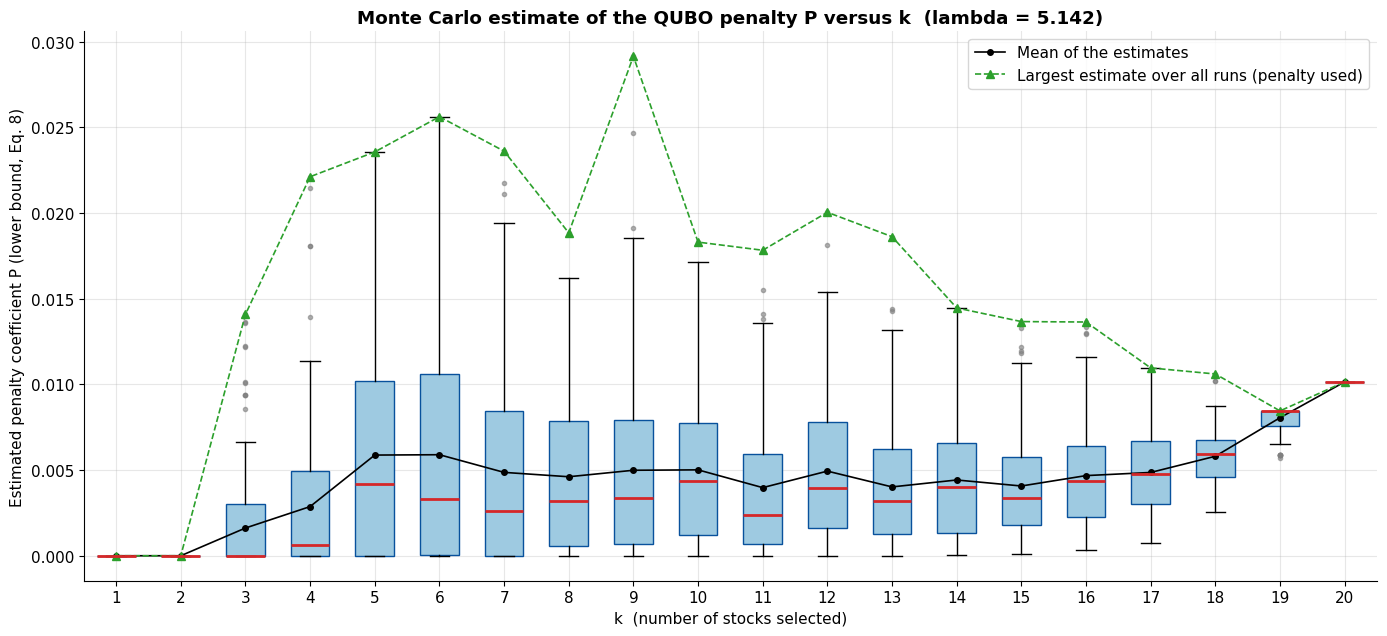

QUBO verification: max |QUBO energy - Markowitz objective| over 300 random feasible vectors for each k = 1.57e-15


In [5]:
# ---- risk aversion lambda -----------------------------------------------------------------------------
r_t, v_t, _, sh_t = port_stats(w_maxsh)
LAMBDA = (r_t - RF) / v_t                                       # first-order condition of the tangency portfolio
w_chk  = mean_variance(mu, Sigma, LAMBDA, MAX_W)
print(f"lambda = (R_t - RF) / var_t = ({r_t:.4f} - {RF:.4f}) / {v_t:.5f} = {LAMBDA:.4f}")
print(f"check: continuous mean-variance optimum at this lambda vs max-Sharpe portfolio -> "
      f"max |weight difference| = {np.abs(w_chk - w_maxsh).max():.2e}  "
      f"(largest weight {w_maxsh.max():.1%}, cap {MAX_W:.0%} binding: {w_maxsh.max() >= MAX_W - 1e-6})")

# ---- Monte Carlo estimate of the penalty P_k (Algorithm 1, Eq. 8) --------------------------------------
K_LIST = list(K_GRID)

def mc_binary_samples(n, m, rng):
    """m random binary vectors; the number of ones of each vector is uniform on 0..n, the positions are random."""
    card = rng.integers(0, n + 1, size=m)
    r = rng.random((m, n))
    thr = np.sort(r, axis=1)[np.arange(m), np.maximum(card - 1, 0)]     # card-th smallest random number
    return ((r <= thr[:, None]) & (card > 0)[:, None]).astype(float)

def penalty_lower_bound(q, lin, s, k, lam):
    """q = x'Sigma x, lin = mu'x, s = sum(x) for every sampled vector."""
    f = 0.5 * lam / k ** 2 * q - lin / k             # objective part of the QUBO
    viol = (s - k) ** 2                              # (A x - b)^2
    v_min = viol.min()
    f_from = f[viol == v_min].min()                  # x_from: least violating sample (best objective among ties)
    m = (f < f_from) & (viol > v_min)                # x_to: samples that gain by breaking the constraint
    if not m.any():
        return 0.0
    return ((f_from - f[m]) / (viol[m] - v_min)).max()

rng_mc = np.random.default_rng(SEED + 7)
MC_P = np.zeros((MC_RUNS, len(K_LIST)))
t0 = time.time()
for run in range(MC_RUNS):
    Xs = mc_binary_samples(N, MC_N, rng_mc)
    q_, lin_, s_ = ((Xs @ Sigma) * Xs).sum(axis=1), Xs @ mu, Xs.sum(axis=1)
    for j, k in enumerate(K_LIST):
        MC_P[run, j] = penalty_lower_bound(q_, lin_, s_, k, LAMBDA)
P_K = MC_P.max(axis=0)                               # largest lower bound over all runs -> penalty used for every k
print(f"Monte Carlo penalty estimate finished in {time.time() - t0:.1f} s "
      f"({MC_RUNS} runs x {MC_N} random binary vectors, {len(K_LIST)} values of k)")

P_TABLE = pd.DataFrame({"k": K_LIST, "P mean": MC_P.mean(axis=0), "P std": MC_P.std(axis=0, ddof=1),
                        "P min": MC_P.min(axis=0), "P median": np.median(MC_P, axis=0), "P max (used)": P_K,
                        "runs with P = 0": (MC_P == 0).sum(axis=0)}).set_index("k")
display(P_TABLE.round(5)); P_TABLE.to_csv(f"{OUT_DIR}/mc_penalty_vs_k.csv")

fig, ax = plt.subplots(figsize=(14, 6.5))
pos = np.arange(len(K_LIST))
ax.boxplot([MC_P[:, j] for j in range(len(K_LIST))], positions=pos, widths=0.6, patch_artist=True,
           boxprops=dict(facecolor="#9ecae1", edgecolor="#08519c"), medianprops=dict(color="#d62728", lw=2),
           flierprops=dict(marker="o", ms=3, markerfacecolor="grey", markeredgecolor="grey", alpha=0.6))
ax.plot(pos, MC_P.mean(axis=0), "ko-", ms=4, lw=1.2, label="Mean of the estimates")
ax.plot(pos, P_K, "^--", color="#2ca02c", ms=6, lw=1.2, label="Largest estimate over all runs (penalty used)")
ax.set_xticks(pos); ax.set_xticklabels(K_LIST); ax.grid(True, alpha=0.3); ax.legend()
ax.set_xlabel("k  (number of stocks selected)"); ax.set_ylabel("Estimated penalty coefficient P (lower bound, Eq. 8)")
ax.set_title(f"Monte Carlo estimate of the QUBO penalty P versus k  (lambda = {LAMBDA:.3f})", fontweight="bold")
plt.tight_layout(); savefig("mc_penalty_vs_k"); plt.show()

# ---- the QUBO matrix and its verification --------------------------------------------------------------
def build_qubo(k, P):
    """H(x) = lambda/2 (x'Sigma x)/k^2 - mu'x/k + P (sum(x) - k)^2 = x'Qx + const, x in {0,1}^N"""
    Q = 0.5 * LAMBDA / k ** 2 * Sigma - np.diag(mu / k) + P * (np.ones((N, N)) - 2 * k * np.eye(N))
    return Q, P * k ** 2

# verification: for every feasible x (sum = k) the QUBO energy must equal the Markowitz objective lambda/2 w'Sigma w - mu'w, w = x/k
rng_v = np.random.default_rng(SEED + 3)
max_err = 0.0
for j, k in enumerate(K_LIST):
    Q, c = build_qubo(k, P_K[j])
    Z = np.zeros((300, N))
    for r in range(300):
        Z[r, rng_v.choice(N, k, replace=False)] = 1.0
    E = ((Z @ Q) * Z).sum(axis=1) + c
    W = Z / k
    obj = 0.5 * LAMBDA * ((W @ Sigma) * W).sum(axis=1) - W @ mu
    max_err = max(max_err, float(np.abs(E - obj).max()))
print(f"QUBO verification: max |QUBO energy - Markowitz objective| over 300 random feasible vectors for each k = {max_err:.2e}")
assert max_err < 1e-9

## 6. Classical solver 1: simulated annealing on the QUBO

**Algorithm.** Many parallel chains start from random bit strings. At temperature T a proposed flip with energy change ΔE is accepted with probability min(1, e^(−ΔE/T)). Every sweep proposes *n* single-bit flips and *n* two-bit flips (two-bit flips can swap one stock for another and so keep Σx = k). Temperature falls geometrically over the sweeps (start = 0.1 × median |ΔE| of the initial state, end = 10⁻⁴ of the start).

**Decoding.** Of the 10 lowest-energy chains, a chain with Σx ≠ k is repaired greedily (add/remove the stock that gives the best objective) and the best portfolio is kept.

This cell only defines the solver functions (`simulated_annealing`, `repair_select`, `decode_select`, `chain_objectives`, `exact_select`).

In [6]:
# ---- simulated annealing on a QUBO  x'Qx,  x in {0,1}^n ------------------------------------------------
def simulated_annealing(Q, n_chains, n_sweeps, rng, t_scale=0.1):
    """Many parallel Metropolis chains with a geometric cooling schedule. Every sweep proposes n single-bit flips and
    n two-bit flips. Returns the final states (chains x n) and their energies x'Qx."""
    Q = 0.5 * (Q + Q.T)
    n = Q.shape[0]
    d = np.diag(Q).copy()
    off = Q - np.diag(d)
    X = rng.integers(0, 2, size=(n_chains, n)).astype(float)
    H = X @ off                                                  # H[r, i] = sum_j off[i, j] x[r, j]
    t_hi = t_scale * np.median(np.abs((1 - 2 * X) * (d + 2 * H)))     # start temperature: fraction of a typical flip cost
    temps = np.geomspace(t_hi, t_hi * 1e-4, n_sweeps)
    for T in temps:
        U1 = rng.random((n, n_chains))
        for j, i in enumerate(rng.permutation(n)):               # single-bit flips
            delta = 1 - 2 * X[:, i]
            dE = delta * (d[i] + 2 * H[:, i])
            acc = (dE <= 0) | (U1[j] < np.exp(-np.maximum(dE, 0) / T))
            if acc.any():
                m = acc * delta
                X[:, i] += m; H += m[:, None] * off[i]
        U2 = rng.random((n, n_chains))
        pi = rng.integers(0, n, size=n); pk = (pi + rng.integers(1, n, size=n)) % n      # two distinct bits
        for j in range(n):                                       # two-bit flips
            i, k_ = pi[j], pk[j]
            di, dk = 1 - 2 * X[:, i], 1 - 2 * X[:, k_]
            dE = di * (d[i] + 2 * H[:, i]) + dk * (d[k_] + 2 * H[:, k_]) + 2 * off[i, k_] * di * dk
            acc = (dE <= 0) | (U2[j] < np.exp(-np.maximum(dE, 0) / T))
            if acc.any():
                mi, mk = acc * di, acc * dk
                X[:, i] += mi; X[:, k_] += mk
                H += mi[:, None] * off[i] + mk[:, None] * off[k_]
    return X, ((X @ Q) * X).sum(axis=1)

# ---- turning annealer output (bits) into portfolios ------------------------------------------------------
def select_objective(u, k):
    w = u / k
    return float(0.5 * LAMBDA * w @ Sigma @ w - mu @ w)

def repair_select(x, k):
    """If a chain ends with sum(x) != k: greedily remove / add the stock that gives the best objective, until sum(x) = k."""
    u = x.astype(float).copy()
    s = Sigma @ u; q = float(u @ s); m = float(mu @ u); c = int(round(u.sum()))
    dg = np.diag(Sigma)
    while c > k:
        idx = np.flatnonzero(u > 0.5)
        f = 0.5 * LAMBDA * (q - 2 * s[idx] + dg[idx]) / k ** 2 - (m - mu[idx]) / k
        j = idx[int(np.argmin(f))]
        q += -2 * s[j] + dg[j]; m -= mu[j]; s = s - Sigma[:, j]; u[j] = 0.0; c -= 1
    while c < k:
        idx = np.flatnonzero(u < 0.5)
        f = 0.5 * LAMBDA * (q + 2 * s[idx] + dg[idx]) / k ** 2 - (m + mu[idx]) / k
        j = idx[int(np.argmin(f))]
        q += 2 * s[j] + dg[j]; m += mu[j]; s = s + Sigma[:, j]; u[j] = 1.0; c += 1
    return u

def decode_select(X, E, k, top=10):
    """Best portfolio among the `top` lowest-energy chains (after repair). Returns (bits, objective)."""
    best_u, best_f = None, np.inf
    for r in np.argsort(E)[:top]:
        u = repair_select(X[r], k)
        f = select_objective(u, k)
        if f < best_f:
            best_u, best_f = u, f
    return best_u, best_f

def chain_objectives(X, k):
    """Objective of the portfolio of EVERY chain (after repair)."""
    return np.array([select_objective(repair_select(x, k), k) for x in X])

def exact_select(k, chunk=40000):
    """Exhaustive search over all C(N,k) equal-weight portfolios. Returns (best index set, best objective)."""
    best_f, best_c = np.inf, None
    it = combinations(range(N), k)
    while True:
        block = list(islice(it, chunk))
        if not block:
            break
        c = np.array(block)
        var = Sigma[c[:, :, None], c[:, None, :]].sum(axis=(1, 2)) / k ** 2
        f = 0.5 * LAMBDA * var - mu[c].sum(axis=1) / k
        j = int(np.argmin(f))
        if f[j] < best_f:
            best_f, best_c = float(f[j]), c[j]
    return best_c, best_f
print("simulated-annealing engine defined")

simulated-annealing engine defined


### 6a. Choosing k: QUBO solved by simulated annealing for every k in `K_GRID`

For every k the QUBO is built with its own penalty P_k and solved by simulated annealing. The **k\*** with the lowest Markowitz objective (λ/2)wᵀΣw − μᵀw is chosen - the same rule as in your notebook. For N = 20 each result is also checked against the exhaustive search over all C(20,k) subsets.
Left chart: all QUBO solutions on the risk-return map; right chart: objective and Sharpe ratio versus k.

QUBO solved for k in [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20] in 8.6 s
simulated annealing = exact optimum for every k: True
k with the lowest objective: k* = 6  (equal weight 16.67% each)


,Exp. return (%),Variance,Volatility (%),Sharpe,Objective (SA),P used,Chains feasible (%),Objective (exact),SA = exact
k,,,,,,,,,
1,10.2369,0.0366,19.1362,0.5349,-0.0082,0.0000,100.0000,-0.0082,True
2,20.1199,0.0544,23.3139,0.8630,-0.0615,0.0000,100.0000,-0.0615,True
3,21.3059,0.0498,22.3104,0.9550,-0.0851,0.0141,100.0000,-0.0851,True
4,27.0140,0.0660,25.6998,1.0511,-0.1003,0.0221,100.0000,-0.1003,True
5,24.1908,0.0513,22.6474,1.0681,-0.1100,0.0236,100.0000,-0.1100,True
6,22.2617,0.0431,20.7546,1.0726,-0.1119,0.0256,100.0000,-0.1119,True
7,20.6062,0.0375,19.3578,1.0645,-0.1097,0.0236,100.0000,-0.1097,True
8,21.1444,0.0403,20.0790,1.0531,-0.1078,0.0188,100.0000,-0.1078,True
9,19.9810,0.0365,19.0999,1.0461,-0.1060,0.0291,100.0000,-0.1060,True


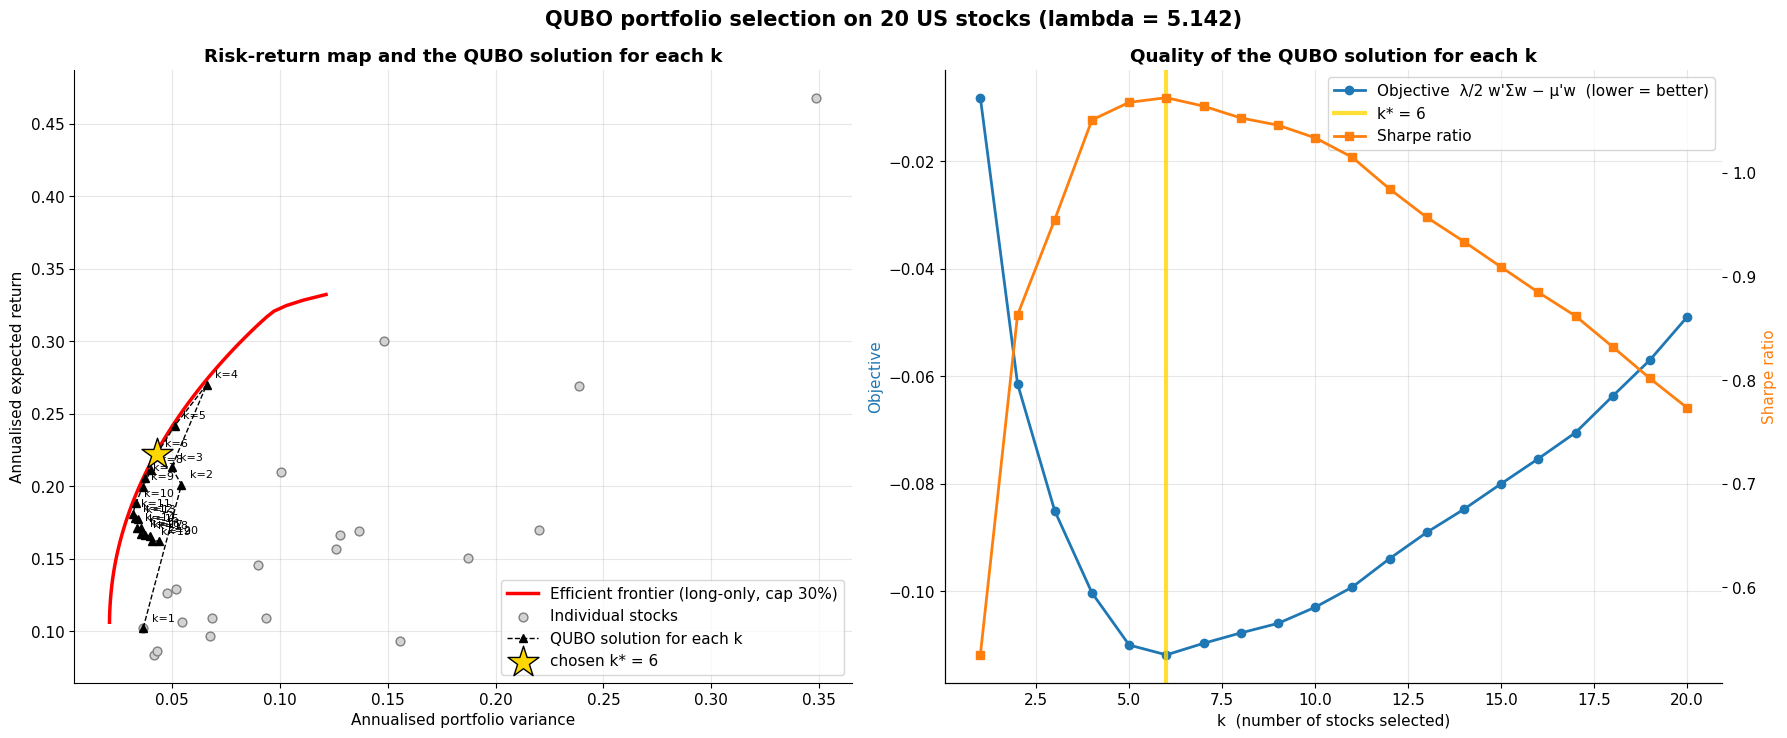

In [7]:
# ---- solve the QUBO for every k in K_GRID with simulated annealing; pick the k with the lowest objective ----
rows, SOL = [], {}
t0 = time.time()
for j, k in enumerate(K_LIST):
    Q, c = build_qubo(k, P_K[j])
    X, E = simulated_annealing(Q, SA_CHAINS, SA_SWEEPS, np.random.default_rng(SEED + 500 + k))
    u, f_sa = decode_select(X, E, k)
    assert u.sum() == k and np.isclose(u @ Q @ u + c, f_sa)         # no penalty: QUBO energy = objective
    w = u / k; SOL[k] = w
    ret, var, vol, sh = port_stats(w)
    row = {"k": k, "Exp. return (%)": ret * 100, "Variance": var, "Volatility (%)": vol * 100, "Sharpe": sh,
           "Objective (SA)": f_sa, "P used": P_K[j], "Chains feasible (%)": 100 * float((X.sum(axis=1) == k).mean())}
    if comb(N, k) <= EXACT_LIMIT:
        sel_ex, f_ex = exact_select(k)
        row["Objective (exact)"] = f_ex
        row["SA = exact"] = bool(f_sa <= f_ex + 1e-10 and set(np.flatnonzero(u)) == set(sel_ex))
    rows.append(row)
QK = pd.DataFrame(rows).set_index("k")
K_STAR = int(QK["Objective (SA)"].idxmin())
w_star = SOL[K_STAR]
print(f"QUBO solved for k in {K_LIST} in {time.time() - t0:.1f} s")
if "SA = exact" in QK:
    print(f"simulated annealing = exact optimum for every k: {bool(QK['SA = exact'].all())}")
print("=" * 78); print(f"k with the lowest objective: k* = {K_STAR}  (equal weight {100 / K_STAR:.2f}% each)"); print("=" * 78)
display(QK.round(4)); QK.to_csv(f"{OUT_DIR}/qubo_scan_over_k.csv")

fig, axes = plt.subplots(1, 2, figsize=(18, 7.5))
ax = axes[0]
ax.plot(f_var, f_ret, color="red", lw=2.5, label=f"Efficient frontier (long-only, cap {MAX_W:.0%})")
ax.scatter(np.diag(Sigma), mu, s=40, color="lightgrey", edgecolor="grey", label="Individual stocks", zorder=3)
qv = np.array([port_stats(SOL[k])[1] for k in K_LIST]); qr = np.array([port_stats(SOL[k])[0] for k in K_LIST])
ax.plot(qv, qr, "k^--", lw=1, ms=6, label="QUBO solution for each k", zorder=5)
for k, x_, y_ in zip(K_LIST, qv, qr):
    ax.annotate(f"k={k}", (x_, y_), xytext=(6, 5), textcoords="offset points", fontsize=8)
rs, vs_, _, _ = port_stats(w_star)
ax.scatter(vs_, rs, marker="*", s=550, color="gold", edgecolor="black", zorder=6, label=f"chosen k* = {K_STAR}")
ax.set_xlabel("Annualised portfolio variance"); ax.set_ylabel("Annualised expected return"); ax.grid(True, alpha=0.3)
ax.legend(loc="lower right"); ax.set_title("Risk-return map and the QUBO solution for each k", fontweight="bold")
ax = axes[1]
ax.plot(K_LIST, QK["Objective (SA)"], "o-", color="#1f77b4", lw=2, label="Objective  λ/2 w'Σw − μ'w  (lower = better)")
ax.axvline(K_STAR, color="gold", lw=3, alpha=0.8, label=f"k* = {K_STAR}")
ax.set_xlabel("k  (number of stocks selected)"); ax.set_ylabel("Objective", color="#1f77b4"); ax.grid(True, alpha=0.3)
ax2 = ax.twinx(); ax2.plot(K_LIST, QK["Sharpe"], "s-", color="#ff7f0e", lw=2, label="Sharpe ratio"); ax2.set_ylabel("Sharpe ratio", color="#ff7f0e")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax.legend(h1 + h2, l1 + l2, loc="best")
ax.set_title("Quality of the QUBO solution for each k", fontweight="bold")
fig.suptitle(f"QUBO portfolio selection on {N} US stocks (lambda = {LAMBDA:.3f})", fontsize=15, fontweight="bold")
plt.tight_layout(); savefig("qubo_scan_over_k"); plt.show()

### 6b. Simulated annealing on the final QUBO (k = k\*), repeated with different random seeds

The QUBO of section 5 for k = k\* is solved `N_SEEDS` times (independent random seeds, `SA_CHAINS` chains × `SA_SWEEPS` sweeps each).
The exact optimum of the equal-weight problem is found by exhaustive search and serves as the reference.

In [8]:
# ---- final QUBO instance (k = k*) and repeated simulated-annealing runs ------------------------------------
K = K_STAR
P_STAR = float(P_K[K_LIST.index(K)])
Q_STAR, C_STAR = build_qubo(K, P_STAR)
print(f"QUBO for k* = {K}: {N} binary variables, {N * (N - 1) // 2} couplings, penalty P = {P_STAR:.5f}")

EXACT_AVAILABLE = comb(N, K) <= EXACT_LIMIT
if EXACT_AVAILABLE:
    t0 = time.time(); sel_exact, F_EXACT = exact_select(K)
    print(f"exhaustive search over all C({N},{K}) = {comb(N, K):,} equal-weight portfolios: optimum {F_EXACT:.6f} "
          f"({time.time() - t0:.1f} s) -> {[tickers[i] for i in sel_exact]}")

SA_RUNS = []
for sd in range(N_SEEDS):
    t0 = time.time()
    X, E = simulated_annealing(Q_STAR, SA_CHAINS, SA_SWEEPS, np.random.default_rng(SEED + 1000 + sd))
    t_run = time.time() - t0
    u, f_best = decode_select(X, E, K)
    SA_RUNS.append(dict(seed=sd, u=u, f=f_best, chain_f=chain_objectives(X, K), feasible=float((X.sum(axis=1) == K).mean()),
                        time=t_run, E_min=float(E.min() + C_STAR)))
print(f"{N_SEEDS} runs of QUBO simulated annealing ({SA_CHAINS} chains x {SA_SWEEPS} sweeps each) finished")
print("best objective of each run:", np.round([r["f"] for r in SA_RUNS][:10], 6), "..." if N_SEEDS > 10 else "")

QUBO for k* = 6: 20 binary variables, 190 couplings, penalty P = 0.02561
exhaustive search over all C(20,6) = 38,760 equal-weight portfolios: optimum -0.111866 (0.1 s) -> ['AAPL', 'NVDA', 'MCD', 'JNJ', 'UNH', 'BRK-B']
30 runs of QUBO simulated annealing (128 chains x 150 sweeps each) finished
best objective of each run: [-0.111866 -0.111866 -0.111866 -0.111866 -0.111866 -0.111866 -0.111866
 -0.111866 -0.111866 -0.111866] ...


## 7. Classical solver 2: MIQP (mixed-integer quadratic programming)

minimise (λ/2)wᵀΣw − μᵀw  s.t.  Σwᵢ = 1,  Σzᵢ = k\*,  0 ≤ wᵢ ≤ zᵢ,  zᵢ ∈ {0,1}

* zᵢ = 1 allows stock *i* to be held, wᵢ is its **continuous** weight - so MIQP also optimises the weights, whereas the QUBO fixes them to 1/k.
* Same μ, Σ and λ as the QUBO. Solver: Gurobi (SCIP if Gurobi is unavailable); Σ is projected to its positive-semidefinite part to remove rounding noise.
* The answer is verified by solving the convex QP of **every** possible k-stock subset (exhaustive check, when C(N,k) is small enough).

In [9]:
# ---- MIQP:  minimise lambda/2 w'Sigma w - mu'w   s.t. sum(w) = 1, sum(z) = k, 0 <= w_i <= z_i, z_i in {0,1} --------
import importlib, subprocess
W_MIN = 0.0
obj_w = lambda w: 0.5 * LAMBDA * float(w @ Sigma @ w) - float(mu @ w)

def _ensure(module, pip_name):
    """import a package; if it is missing, install it into the Python that runs THIS notebook, then import it."""
    try:
        return importlib.import_module(module)
    except ImportError:
        print(f"'{module}' not found in {sys.executable} -> installing '{pip_name}' ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])
        importlib.invalidate_caches()
        return importlib.import_module(module)

ev_, V_ = np.linalg.eigh(Sigma)
Sigma_psd = (V_ * np.clip(ev_, 0, None)) @ V_.T          # Sigma without tiny negative rounding eigenvalues (convex objective)

def solve_gurobi():
    gp = _ensure("gurobipy", "gurobipy")
    from gurobipy import GRB
    m = gp.Model("miqp_k_stocks"); m.Params.OutputFlag = 0; m.Params.MIPGap = MIQP_GAP; m.Params.MIPGapAbs = 1e-12
    if MIQP_TIME_LIMIT is not None:
        m.Params.TimeLimit = MIQP_TIME_LIMIT
    w = m.addMVar(N, lb=0.0, ub=1.0, name="w"); z = m.addMVar(N, vtype=GRB.BINARY, name="z")
    m.setObjective(0.5 * LAMBDA * (w @ Sigma_psd @ w) - mu @ w, GRB.MINIMIZE)
    m.addConstr(w.sum() == 1); m.addConstr(z.sum() == K); m.addConstr(w <= z); m.addConstr(w >= W_MIN * z)
    m.optimize()
    if m.SolCount == 0:
        raise RuntimeError(f"Gurobi status {m.Status}")
    return w.X.copy(), z.X.copy(), f"status {m.Status} (2 = optimal, 9 = time limit), MIP gap {m.MIPGap:.1e}"

def solve_scip():
    sc = _ensure("pyscipopt", "pyscipopt")
    m = sc.Model("miqp_k_stocks"); m.hideOutput(); m.setParam("limits/gap", MIQP_GAP); m.setParam("limits/absgap", 0.0)
    if MIQP_TIME_LIMIT is not None:
        m.setParam("limits/time", MIQP_TIME_LIMIT)
    w = [m.addVar(lb=0.0, ub=1.0, name=f"w{i}") for i in range(N)]
    z = [m.addVar(vtype="B", name=f"z{i}") for i in range(N)]
    t = m.addVar(lb=None, name="t"); m.setObjective(t, "minimize")           # epigraph variable
    m.addCons(t >= 0.5 * LAMBDA * sc.quicksum(float(Sigma_psd[i, j]) * w[i] * w[j] for i in range(N) for j in range(N))
              - sc.quicksum(float(mu[i]) * w[i] for i in range(N)))
    m.addCons(sc.quicksum(w) == 1); m.addCons(sc.quicksum(z) == K)
    for i in range(N):
        m.addCons(w[i] <= z[i]); m.addCons(w[i] >= W_MIN * z[i])
    m.optimize()
    if m.getNSols() == 0:
        raise RuntimeError(f"SCIP status {m.getStatus()}")
    return (np.array([m.getVal(v) for v in w]), np.array([m.getVal(v) for v in z]), f"status {m.getStatus()}, gap {m.getGap():.1e}")

SOLVER = None
for name, fn in [("Gurobi", solve_gurobi), ("SCIP", solve_scip)]:
    t0 = time.time()
    try:
        w_raw, z_raw, status = fn(); SOLVER = name; t_miqp = time.time() - t0; break
    except Exception as e:
        print(f"{name} could not be used: {e}")
if SOLVER is None:
    raise RuntimeError("No MIQP solver worked. In a notebook cell run:  %pip install gurobipy pyscipopt   then restart the kernel.")
w_miqp = np.where(w_raw < 1e-8, 0.0, w_raw); w_miqp /= w_miqp.sum()
z_miqp = np.flatnonzero(np.round(z_raw) > 0.5)
OBJ_MIQP = obj_w(w_miqp)
print(f"MIQP solved with {SOLVER} in {t_miqp:.2f} s  |  {status}  |  objective {OBJ_MIQP:.6f}")

# exhaustive verification (only for small C(N,k)): convex QP of every possible k-stock subset
def qp_subset(idx):
    Ss, ms = Sigma[np.ix_(idx, idx)], mu[idx]
    r = minimize(lambda x: 0.5 * LAMBDA * x @ Ss @ x - ms @ x, np.full(len(idx), 1 / len(idx)),
                 jac=lambda x: LAMBDA * Ss @ x - ms, method="SLSQP", bounds=[(max(W_MIN, 0), 1)] * len(idx),
                 constraints=[{"type": "eq", "fun": lambda x: x.sum() - 1, "jac": lambda x: np.ones(len(x))}],
                 options={"ftol": 1e-14, "maxiter": 500})
    return r.fun, r.x
if comb(N, K) <= ENUM_LIMIT:
    t0 = time.time()
    res = [(qp_subset(np.array(c)), c) for c in combinations(range(N), K)]
    (f_en, x_en), c_en = min(res, key=lambda t: t[0][0])
    print(f"Exhaustive check: {len(res):,} subsets x convex QP in {time.time() - t0:.1f} s | best objective {f_en:.6f} | "
          f"same stocks as MIQP: {set(c_en) == set(z_miqp)} | objective difference {abs(f_en - OBJ_MIQP):.2e}")

held = np.flatnonzero(w_miqp > 1e-6)
print("=" * 78); print(f"MIQP RESULT (k = {K}): " + ",  ".join(f"{tickers[i]} {w_miqp[i] * 100:.2f}%" for i in held[np.argsort(-w_miqp[held])][:15])
                       + (" ..." if len(held) > 15 else "")); print("=" * 78)
if len(held) < K:
    print(f"Note: z selects {K} stocks but only {len(held)} receive a positive weight (the model allows w_i = 0 for a selected stock).")
tab = pd.DataFrame({"Annualised return (%)": mu[held] * 100, "Volatility (%)": np.sqrt(np.diag(Sigma))[held] * 100,
                    "MIQP weight (%)": w_miqp[held] * 100}, index=[tickers[i] for i in held]).sort_values("MIQP weight (%)", ascending=False)
display(tab.round(3)); tab.to_csv(f"{OUT_DIR}/miqp_weights.csv")

Restricted license - for non-production use only - expires 2027-11-29
MIQP solved with Gurobi in 1.03 s  |  status 2 (2 = optimal, 9 = time limit), MIP gap 0.0e+00  |  objective -0.112560
Exhaustive check: 38,760 subsets x convex QP in 95.5 s | best objective -0.112560 | same stocks as MIQP: True | objective difference 1.39e-17
MIQP RESULT (k = 6): UNH 20.30%,  AAPL 19.34%,  JNJ 17.74%,  NVDA 15.96%,  MCD 15.16%,  BRK-B 11.51%


,Annualised return (%),Volatility (%),MIQP weight (%)
UNH,21.017,31.700,20.297
AAPL,30.003,38.516,19.340
JNJ,10.237,19.136,17.739
NVDA,46.799,59.047,15.960
MCD,12.898,22.726,15.155
BRK-B,12.617,21.877,11.508


## 8. Ising spin-glass model

**Mapping.** With xᵢ = (1 + sᵢ)/2, sᵢ ∈ {−1, +1}, the QUBO becomes the Ising energy

E(s) = Σ_{i<j} Jᵢⱼ sᵢ sⱼ + Σᵢ hᵢ sᵢ + offset,  Jᵢⱼ = (Qᵢⱼ+Qⱼᵢ)/4,  hᵢ = Qᵢᵢ/2 + Σ_{j≠i}(Qᵢⱼ+Qⱼᵢ)/4.

* Jᵢⱼ are the couplings between spins (every pair interacts: a fully connected, spin-glass-type model), hᵢ are the local fields.
* **Verification:** E(s) must equal the QUBO energy for every bit string.
* **Solver:** Metropolis simulated annealing *directly on the Ising energy* (single-spin flips with ΔE = −2sᵢFᵢ, F = h + Js, and two-spin flips with the extra term 4Jᵢₖsᵢsₖ), same schedule, chains, sweeps and number of seeds as in section 6b but independent random numbers. This is classical thermal annealing of the Ising Hamiltonian; no quantum hardware is used.
* The table shows the Ising parameters; the last row gives how much of the mean coupling comes from the constraint penalty.

In [10]:
# ---- QUBO -> Ising:  x_i = (1 + s_i)/2,  s_i in {-1,+1} ----------------------------------------------------
#   x'Qx + const = sum_{i<j} J_ij s_i s_j + sum_i h_i s_i + offset
#   J_ij   = (Q_ij + Q_ji)/4                                   (i < j)
#   h_i    = Q_ii/2 + sum_{j != i} (Q_ij + Q_ji)/4
#   offset = const + sum_i Q_ii/2 + sum_{i<j} (Q_ij + Q_ji)/4
def qubo_to_ising(Q, const):
    Qs = Q + Q.T
    Jf = np.triu(Qs, 1) / 4.0
    Jf = Jf + Jf.T                                                     # symmetric, zero diagonal
    h = np.diag(Q) / 2.0 + Jf.sum(axis=1)
    offset = const + np.diag(Q).sum() / 2.0 + np.triu(Qs, 1).sum() / 4.0
    return Jf, h, offset

J_FULL, H_FIELD, OFFSET = qubo_to_ising(Q_STAR, C_STAR)
def ising_energy(S):
    """E(s) = sum_{i<j} J_ij s_i s_j + sum_i h_i s_i + offset   for every row s of S"""
    return 0.5 * ((S @ J_FULL) * S).sum(axis=1) + S @ H_FIELD + OFFSET

# verification: the Ising energy must equal the QUBO energy x'Qx + const for EVERY bit string (feasible or not)
rng_i = np.random.default_rng(SEED + 5)
S_t = rng_i.choice([-1.0, 1.0], size=(5000, N)); X_t = (1 + S_t) / 2
err = np.abs(ising_energy(S_t) - (((X_t @ Q_STAR) * X_t).sum(axis=1) + C_STAR)).max()
print(f"Ising verification: max |E_Ising(s) - E_QUBO(x)| over 5000 random spin vectors = {err:.2e}")
assert err < 1e-9

iu = np.triu_indices(N, 1); Jv = J_FULL[iu]
spin_tab = pd.DataFrame({"value": {
    "number of spins": N, "number of couplings J_ij": len(Jv), "J mean": Jv.mean(), "J std": Jv.std(), "J min": Jv.min(),
    "J max": Jv.max(), "fraction of J_ij > 0 (antiferromagnetic)": float((Jv > 0).mean()), "h mean": H_FIELD.mean(),
    "h std": H_FIELD.std(), "h min": H_FIELD.min(), "h max": H_FIELD.max(),
    "penalty share of mean J  (P/2) / mean(J)": (P_STAR / 2) / Jv.mean()}})
print("Ising (spin-glass) parameters of the k* problem:"); display(spin_tab.round(6))

# ---- simulated annealing on the Ising energy (spin-flip Metropolis) ----------------------------------------
def ising_annealing(J, h, n_chains, n_sweeps, rng, t_scale=0.1):
    """Parallel Metropolis chains on  E(s) = 1/2 s'Js + h's  (J symmetric, zero diagonal).
    Flipping spin i costs  dE_i = -2 s_i F_i  with local field F_i = h_i + sum_j J_ij s_j.
    Flipping spins i and k together costs  -2 s_i F_i - 2 s_k F_k + 4 J_ik s_i s_k."""
    n = len(h)
    S = rng.choice([-1.0, 1.0], size=(n_chains, n))
    F = h[None, :] + S @ J
    t_hi = t_scale * np.median(np.abs(-2 * S * F))
    temps = np.geomspace(t_hi, t_hi * 1e-4, n_sweeps)
    for T in temps:
        U1 = rng.random((n, n_chains))
        for j, i in enumerate(rng.permutation(n)):                 # single-spin flips
            dE = -2 * S[:, i] * F[:, i]
            acc = (dE <= 0) | (U1[j] < np.exp(-np.maximum(dE, 0) / T))
            if acc.any():
                dsi = acc * (-2 * S[:, i])                         # change of s_i (0 where rejected)
                S[:, i] += dsi; F += dsi[:, None] * J[i]
        U2 = rng.random((n, n_chains))
        pi = rng.integers(0, n, size=n); pk = (pi + rng.integers(1, n, size=n)) % n
        for j in range(n):                                         # two-spin flips
            i, k_ = pi[j], pk[j]
            dE = -2 * S[:, i] * F[:, i] - 2 * S[:, k_] * F[:, k_] + 4 * J[i, k_] * S[:, i] * S[:, k_]
            acc = (dE <= 0) | (U2[j] < np.exp(-np.maximum(dE, 0) / T))
            if acc.any():
                dsi, dsk = acc * (-2 * S[:, i]), acc * (-2 * S[:, k_])
                S[:, i] += dsi; S[:, k_] += dsk
                F += dsi[:, None] * J[i] + dsk[:, None] * J[k_]
    return S

ISING_RUNS = []
for sd in range(N_SEEDS):
    t0 = time.time()
    S = ising_annealing(J_FULL, H_FIELD, SA_CHAINS, SA_SWEEPS, np.random.default_rng(SEED + 2000 + sd))
    t_run = time.time() - t0
    X = (1 + S) / 2                                                # spins -> bits
    E_is = ising_energy(S)
    assert np.allclose(E_is, ((X @ Q_STAR) * X).sum(axis=1) + C_STAR, atol=1e-9)
    u, f_best = decode_select(X, E_is, K)
    ISING_RUNS.append(dict(seed=sd, u=u, f=f_best, chain_f=chain_objectives(X, K), feasible=float((X.sum(axis=1) == K).mean()),
                           time=t_run, E_min=float(E_is.min())))
print(f"{N_SEEDS} runs of Ising simulated annealing ({SA_CHAINS} chains x {SA_SWEEPS} sweeps each) finished")
print("best objective of each run:", np.round([r["f"] for r in ISING_RUNS][:10], 6), "..." if N_SEEDS > 10 else "")

Ising verification: max |E_Ising(s) - E_QUBO(x)| over 5000 random spin vectors = 8.88e-16
Ising (spin-glass) parameters of the k* problem:


,value
number of spins,20.000000
number of couplings J_ij,190.000000
J mean,0.014241
J std,0.000935
J min,0.013170
J max,0.017681
fraction of J_ij > 0 (antiferromagnetic),1.000000
h mean,0.120428
h std,0.010612
h min,0.108081


30 runs of Ising simulated annealing (128 chains x 150 sweeps each) finished
best objective of each run: [-0.111866 -0.111866 -0.111866 -0.111866 -0.111866 -0.111866 -0.111866
 -0.111866 -0.111866 -0.111866] ...


## 9. Comparison: simulated annealing (QUBO) vs Ising spin-glass model vs MIQP - 20 US stocks

* **Table 1** - the best portfolio of each method (return, volatility, Sharpe, objective, gap to the reference and to MIQP, time).
* **Table 2** - behaviour of the two annealers over all repeated runs (runs that reached the reference, share of chains at the reference, share of feasible chains, time).
* **Charts** - the three portfolios on the risk-return map, and the objective reached by every annealing chain.
* **Statement** - printed by the code from the numbers above (including a Welch t-test on the per-run success shares).

COMPARISON TABLE - 20 US stocks, k* = 6, lambda = 5.1422
reference = exact optimum of the equal-weight problem (all C(20,6) subsets): -0.111866


,No. of stocks,Weights,Exp. return (%),Variance,Volatility (%),Sharpe,Objective,Gap to reference,Time per run (s),Gap to MIQP,Stocks
Method,,,,,,,,,,,
Simulated annealing (QUBO),6,equal (1/k),22.261725,0.043075,20.754577,1.072618,-0.111866,0.000000,0.284137,0.000694,"AAPL, NVDA, MCD, JNJ, UNH, BRK-B"
Ising spin glass (SA on Ising),6,equal (1/k),22.261725,0.043075,20.754577,1.072618,-0.111866,0.000000,0.232031,0.000694,"AAPL, NVDA, MCD, JNJ, UNH, BRK-B"
MIQP (Gurobi),6,optimised,22.760213,0.044744,21.152852,1.075988,-0.112560,-0.000694,1.032761,0.000000,"AAPL, NVDA, MCD, JNJ, UNH, BRK-B"


Repeated-run statistics of the two annealers:


,Simulated annealing (QUBO),Ising spin glass (SA on Ising)
runs (seeds),30,30
chains x sweeps per run,128 x 150,128 x 150
best objective over all runs,-0.111866,-0.111866
runs that reached the reference,30 / 30,30 / 30
chains at the reference (%) mean ± std,100.00 ± 0.00,100.00 ± 0.00
chains with sum(x) = k (%) mean ± std,100.00 ± 0.00,100.00 ± 0.00
time per run (s) mean,0.28,0.23


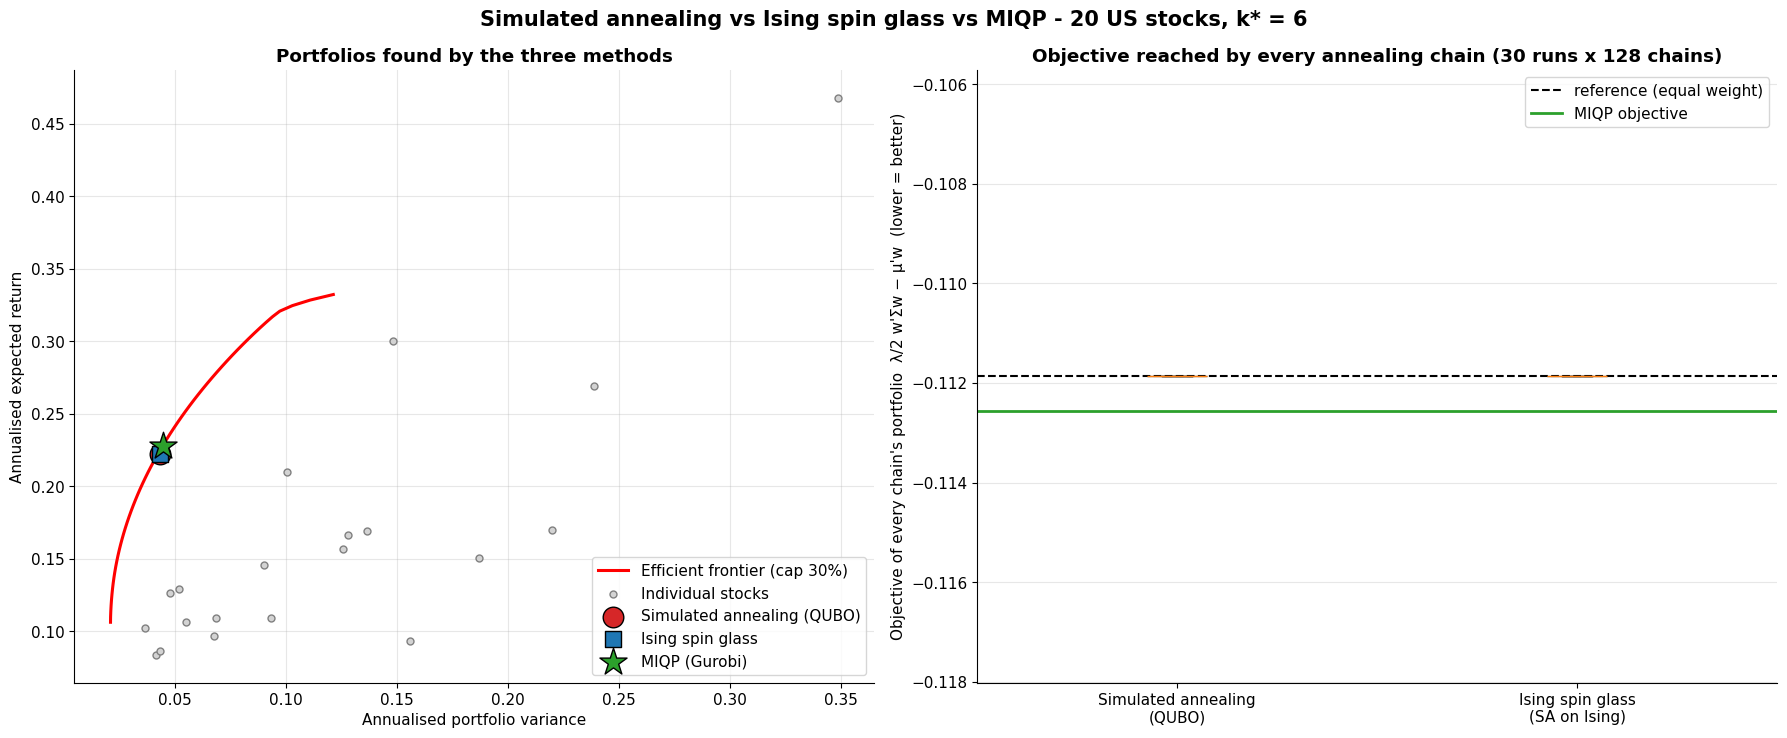

STATEMENT ON THE COMPARED RESULTS
1. Both annealers solve the same problem: the Ising energy equals the QUBO energy for every bit string (max difference 8.9e-16), so the two landscapes are identical and differ only by the change of variables x = (1+s)/2.
2. Best portfolio found: simulated annealing objective -0.111866, Ising -0.111866; same stocks selected: True; reference -0.111866 (exact optimum of the equal-weight problem (all C(20,6) subsets)).
3. Runs that reached the reference: simulated annealing 30/30, Ising 30/30. Chains at the reference: 100.00 ± 0.00 % (SA) vs 100.00 ± 0.00 % (Ising). The share of chains at the reference is the same in every run for both annealers (no variance to test).
4. MIQP (free weights, same k and lambda): objective -0.112560, Sharpe 1.0760, solved in 1.03 s with Gurobi (status 2 (2 = optimal, 9 = time limit), MIP gap 0.0e+00). The equal-weight annealing solutions are +0.000694 (SA) / +0.000694 (Ising) away from it; this gap is the price of the equal w

In [11]:
# ---- reference value ------------------------------------------------------------------------------------
all_best = min(min(r["f"] for r in SA_RUNS), min(r["f"] for r in ISING_RUNS))
if EXACT_AVAILABLE:
    REF, REF_NAME = F_EXACT, f"exact optimum of the equal-weight problem (all C({N},{K}) subsets)"
else:
    REF, REF_NAME = all_best, "best equal-weight objective found by any annealing run (no exhaustive search possible)"
TOL = 1e-10

def run_stats(runs):
    hits = np.array([float(np.mean(r["chain_f"] <= REF + TOL)) for r in runs])
    best = np.array([r["f"] for r in runs])
    return dict(hit=hits, best=best, feas=np.array([r["feasible"] for r in runs]), time=np.array([r["time"] for r in runs]),
                seeds_at_ref=int((best <= REF + TOL).sum()))
st_sa, st_is = run_stats(SA_RUNS), run_stats(ISING_RUNS)

def best_run(runs):
    r = min(runs, key=lambda r: r["f"]); return r["u"] / K
w_sa, w_is = best_run(SA_RUNS), best_run(ISING_RUNS)

# ---- table 1: the portfolios -----------------------------------------------------------------------------
def row(name, w, t):
    ret, var, vol, sh = port_stats(w)
    return {"Method": name, "No. of stocks": int((w > 1e-6).sum()), "Weights": "equal (1/k)" if name != "MIQP (Gurobi/SCIP)" else "optimised",
            "Exp. return (%)": ret * 100, "Variance": var, "Volatility (%)": vol * 100, "Sharpe": sh,
            "Objective": mv_objective(w, mu, Sigma, LAMBDA), "Gap to reference": mv_objective(w, mu, Sigma, LAMBDA) - REF,
            "Time per run (s)": t}
rows = [row("Simulated annealing (QUBO)", w_sa, st_sa["time"].mean()),
        row("Ising spin glass (SA on Ising)", w_is, st_is["time"].mean()),
        row("MIQP (Gurobi/SCIP)", w_miqp, t_miqp)]
rows[2]["Method"] = f"MIQP ({SOLVER})"; rows[2]["Weights"] = "optimised"
rows[0]["Weights"] = rows[1]["Weights"] = "equal (1/k)"
COMP = pd.DataFrame(rows).set_index("Method")
COMP["Gap to MIQP"] = COMP["Objective"] - OBJ_MIQP
COMP["Stocks"] = [", ".join(tickers[i] for i in np.flatnonzero(w > 1e-6)[:K][:12]) + (" ..." if (w > 1e-6).sum() > 12 else "")
                  for w in (w_sa, w_is, w_miqp)]
print(f"COMPARISON TABLE - {N} US stocks, k* = {K}, lambda = {LAMBDA:.4f}")
print(f"reference = {REF_NAME}: {REF:.6f}")
display(COMP.round(6)); COMP.to_csv(f"{OUT_DIR}/comparison_portfolios.csv")

# ---- table 2: behaviour of the two annealers over repeated runs --------------------------------------------
def mean_std(a, pct=False):
    a = a * 100 if pct else a
    return f"{a.mean():.2f} ± {a.std(ddof=1):.2f}" if len(a) > 1 else f"{a.mean():.2f}"
STAT = pd.DataFrame({
    "Simulated annealing (QUBO)": {"runs (seeds)": N_SEEDS, "chains x sweeps per run": f"{SA_CHAINS} x {SA_SWEEPS}",
        "best objective over all runs": min(r["f"] for r in SA_RUNS), "runs that reached the reference": f"{st_sa['seeds_at_ref']} / {N_SEEDS}",
        "chains at the reference (%)  mean ± std": mean_std(st_sa["hit"], True), "chains with sum(x) = k (%)  mean ± std": mean_std(st_sa["feas"], True),
        "time per run (s)  mean": round(st_sa["time"].mean(), 2)},
    "Ising spin glass (SA on Ising)": {"runs (seeds)": N_SEEDS, "chains x sweeps per run": f"{SA_CHAINS} x {SA_SWEEPS}",
        "best objective over all runs": min(r["f"] for r in ISING_RUNS), "runs that reached the reference": f"{st_is['seeds_at_ref']} / {N_SEEDS}",
        "chains at the reference (%)  mean ± std": mean_std(st_is["hit"], True), "chains with sum(x) = k (%)  mean ± std": mean_std(st_is["feas"], True),
        "time per run (s)  mean": round(st_is["time"].mean(), 2)}})
print("Repeated-run statistics of the two annealers:"); display(STAT); STAT.to_csv(f"{OUT_DIR}/comparison_annealers.csv")

# ---- charts ----------------------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(18, 7.5))
ax = axes[0]
ax.plot(f_var, f_ret, color="red", lw=2.2, label=f"Efficient frontier (cap {MAX_W:.0%})")
ax.scatter(np.diag(Sigma), mu, s=25, color="lightgrey", edgecolor="grey", label="Individual stocks", zorder=2)
for lab, w, mk, col_, sz in [("Simulated annealing (QUBO)", w_sa, "o", "#d62728", 220), ("Ising spin glass", w_is, "s", "#1f77b4", 130),
                             (f"MIQP ({SOLVER})", w_miqp, "*", "#2ca02c", 420)]:
    r_, v_, _, _ = port_stats(w); ax.scatter(v_, r_, marker=mk, s=sz, color=col_, edgecolor="black", zorder=5, label=lab)
ax.set_xlabel("Annualised portfolio variance"); ax.set_ylabel("Annualised expected return"); ax.grid(True, alpha=0.3)
ax.legend(loc="lower right"); ax.set_title("Portfolios found by the three methods", fontweight="bold")
ax = axes[1]
data = [np.concatenate([r["chain_f"] for r in SA_RUNS]), np.concatenate([r["chain_f"] for r in ISING_RUNS])]
bp = ax.boxplot(data, patch_artist=True, showfliers=True, flierprops=dict(marker="o", ms=2, alpha=0.4))
ax.set_xticklabels(["Simulated annealing\n(QUBO)", "Ising spin glass\n(SA on Ising)"])
for patch, c in zip(bp["boxes"], ["#d62728", "#1f77b4"]):
    patch.set_facecolor(c); patch.set_alpha(0.5)
ax.axhline(REF, color="black", ls="--", lw=1.5, label="reference (equal weight)")
ax.axhline(OBJ_MIQP, color="#2ca02c", ls="-", lw=2, label=f"MIQP objective")
ax.set_ylabel("Objective of every chain's portfolio  λ/2 w'Σw − μ'w  (lower = better)"); ax.grid(True, axis="y", alpha=0.3); ax.legend()
ax.set_title(f"Objective reached by every annealing chain ({N_SEEDS} runs x {SA_CHAINS} chains)", fontweight="bold")
fig.suptitle(f"Simulated annealing vs Ising spin glass vs MIQP - {N} US stocks, k* = {K}", fontsize=15, fontweight="bold")
plt.tight_layout(); savefig("comparison"); plt.show()

# ---- statement (generated from the numbers above) --------------------------------------------------------
same_set = set(np.flatnonzero(w_sa)) == set(np.flatnonzero(w_is))
if N_SEEDS > 1 and (st_sa["hit"].std() > 0 or st_is["hit"].std() > 0):
    p_val = float(stats.ttest_ind(st_sa["hit"], st_is["hit"], equal_var=False).pvalue)
    test_txt = (f"A Welch t-test on the per-run share of chains at the reference gives p = {p_val:.3f}, so the difference between "
                f"the two annealers is {'not ' if p_val > 0.05 else ''}statistically significant at the 5% level.")
else:
    test_txt = "The share of chains at the reference is the same in every run for both annealers (no variance to test)."
print("=" * 100); print("STATEMENT ON THE COMPARED RESULTS"); print("=" * 100)
print(f"1. Both annealers solve the same problem: the Ising energy equals the QUBO energy for every bit string (max difference {err:.1e}), "
      f"so the two landscapes are identical and differ only by the change of variables x = (1+s)/2.")
print(f"2. Best portfolio found: simulated annealing objective {min(r['f'] for r in SA_RUNS):.6f}, Ising {min(r['f'] for r in ISING_RUNS):.6f}; "
      f"same stocks selected: {same_set}; reference {REF:.6f} ({REF_NAME}).")
print(f"3. Runs that reached the reference: simulated annealing {st_sa['seeds_at_ref']}/{N_SEEDS}, Ising {st_is['seeds_at_ref']}/{N_SEEDS}. "
      f"Chains at the reference: {mean_std(st_sa['hit'], True)} % (SA) vs {mean_std(st_is['hit'], True)} % (Ising). {test_txt}")
print(f"4. MIQP (free weights, same k and lambda): objective {OBJ_MIQP:.6f}, Sharpe {port_stats(w_miqp)[3]:.4f}, solved in {t_miqp:.2f} s with {SOLVER} ({status}). "
      f"The equal-weight annealing solutions are {min(r['f'] for r in SA_RUNS) - OBJ_MIQP:+.6f} (SA) / {min(r['f'] for r in ISING_RUNS) - OBJ_MIQP:+.6f} (Ising) "
      f"away from it; this gap is the price of the equal weights 1/k that the binary encoding imposes.")
print(f"5. Run time per annealing run: {st_sa['time'].mean():.2f} s (SA) vs {st_is['time'].mean():.2f} s (Ising); MIQP {t_miqp:.2f} s.")